# Success rate comparison: Chinese vs German

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from datetime import datetime, timedelta


In [2]:
# with opened ANKI
ANKI_URL = "http://127.0.0.1:8765"
DECKS = {
    "chinese": "#2a78d6",  # blue
    "german": "#1baf7a",   # aqua
}
DAYS_BACK = 365          # 30 for last month, 365 for last year


In [3]:
def load_reviews(deck_name, days_back):

    cutoff_timestamp_ms = int((datetime.now() - timedelta(days=days_back)).timestamp() * 1000)

    payload = {
        "action": "cardReviews",
        "version": 6,
        "params": {
            "deck": deck_name,
            "startID": cutoff_timestamp_ms
        }
    }

    try:
        response = requests.post(ANKI_URL, json=payload).json()
    except requests.exceptions.ConnectionError:
        print("Error: Anki is not running or AnkiConnect is not installed.")
        exit(1)

    if response.get("error"):
        print(f"API Error: {response['error']}")
        exit(1)

    reviews = response["result"]

    # Group by day
    daily_stats = {}
    for entry in reviews:
        # entry structure: [review_time_ms, card_id, usn, ease, interval, last_interval, factor, time, type]
        rev_id, card_id, _, ease = entry[:4]

        day_str = datetime.fromtimestamp(rev_id / 1000).strftime('%Y-%m-%d')
        if day_str not in daily_stats:
            daily_stats[day_str] = {"pass": 0, "fail": 0}

        if ease == 1:
            daily_stats[day_str]["fail"] += 1
        else:
            daily_stats[day_str]["pass"] += 1

    # Create a DataFrame from the daily stats
    df = pd.DataFrame.from_dict(daily_stats, orient='index')
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    df["pct"] = df["pass"] / (df["pass"] + df["fail"]) * 100
    df["date"] = df.index
    df.reset_index(drop=True, inplace=True)

    # Days relative to today (negative = in the past), so decks with different
    # review-history lengths still line up on a shared, real time axis.
    today = pd.Timestamp(datetime.now().date())
    df["n_day"] = (df["date"] - today).dt.days

    df["pct_rolling_7"] = df["pct"].rolling(window=7).mean()

    # drop outliers (more than 3 std from the mean) so a single noisy day
    # doesn't stretch the shared y-axis
    mean_pct, std_pct = df["pct"].mean(), df["pct"].std()
    df = df[(df["pct"] <= mean_pct + 3 * std_pct) & (df["pct"] >= mean_pct - 3 * std_pct)]

    return df


In [4]:
deck_data = {deck: load_reviews(deck, DAYS_BACK) for deck in DECKS}
{deck: df.tail() for deck, df in deck_data.items()}


{'chinese':      pass  fail        pct       date  n_day  pct_rolling_7
 334   145    22  86.826347 2026-09-23     -4      78.702494
 335   138    46  75.000000 2026-09-24     -3      78.487348
 336   156    29  84.324324 2026-09-25     -2      79.836320
 337   148    31  82.681564 2026-09-26     -1      80.544719
 338   130    30  81.250000 2026-09-27      0      80.527212,
 'german':      pass  fail        pct       date  n_day  pct_rolling_7
 236   183    21  89.705882 2026-09-23     -4      83.110170
 237   172    22  88.659794 2026-09-24     -3      84.534637
 238   173    25  87.373737 2026-09-25     -2      85.376388
 239   174    15  92.063492 2026-09-26     -1      86.266893
 240   185    35  84.090909 2026-09-27      0      87.720874}

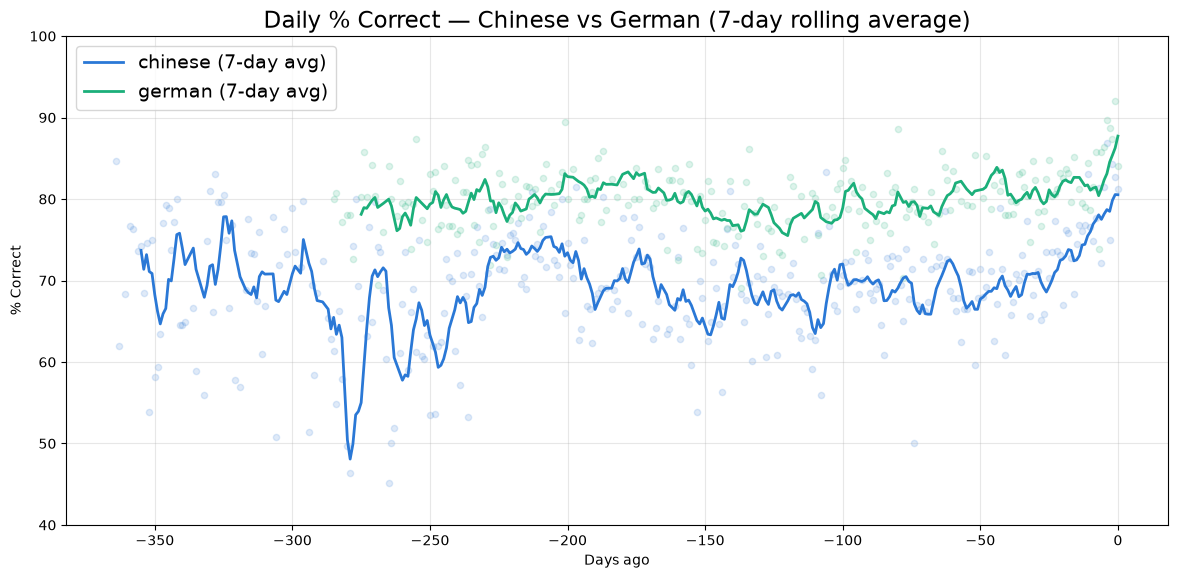

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.rcParams.update({'font.size': 14})

for deck, color in DECKS.items():
    df = deck_data[deck]
    ax.scatter(df["n_day"], df["pct"], color=color, alpha=0.15, s=20)
    ax.plot(df["n_day"], df["pct_rolling_7"], color=color, linewidth=2, label=f"{deck} (7-day avg)")

ax.set_title("Daily % Correct \u2014 Chinese vs German (7-day rolling average)")
ax.set_xlabel("Days ago")
ax.set_ylabel("% Correct")
ax.set_ylim(40, 100)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [6]:
# check the correlation between the two decks' daily % correct
# crop df only where the two decks overlap in time, so we don't get a spurious correlation from the fact that one deck has more data than the other
cropped_chinese_df = deck_data["chinese"][deck_data["chinese"]["date"].isin(deck_data["german"]["date"])]
#merged_df = pd.merge(deck_data["chinese"][["date", "pct"]], deck_data["german"][["date", "pct"]], on="date", suffixes=("_chinese", "_german"))
merged_df = pd.merge(cropped_chinese_df[["date", "pct"]], deck_data["german"][["date", "pct"]], on="date", suffixes=("_chinese", "_german"))
correlation = merged_df["pct_chinese"].corr(merged_df["pct_german"])

In [7]:
# calculate p-value for the correlation
from scipy.stats import pearsonr
_, p_value = pearsonr(merged_df["pct_chinese"], merged_df["pct_german"])
print(f"Correlation: {correlation:.4f}, p-value: {p_value:.4f}")

Correlation: 0.1475, p-value: 0.0247
